# Authorship Feature Analysis

Idea of this notebook is to investigate which character-level n-grams distinguish language models using the best baseline from notebook 01: character TF-IDF (2–5) + LinearSVC.

## 1. Load data

In [27]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import balanced_accuracy_score, recall_score, classification_report
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

train_path = PROJECT_ROOT / "data" / "train.csv"
train_df = pd.read_csv(train_path).reset_index(drop=True)

required_columns = {"text", "model", "prompt_id"}
missing = required_columns - set(train_df.columns)
if missing:
    raise ValueError(f"Missing columns in train.csv: {sorted(missing)}")

X = train_df["text"].fillna("")
y = train_df["model"]
groups = train_df["prompt_id"]

print("Shape:", train_df.shape)
print("Unique prompts:", groups.nunique())
display(train_df.head(3))
display(y.value_counts().rename("count"))

Shape: (2699, 4)
Unique prompts: 150


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash


model
qwen3.8-max               150
claude-sonnet-5           150
gemini-3.6-flash          150
gpt-5.6-terra             150
glm-5.3-flash             150
gemini-3.1-pro-preview    150
gemini-3.8-flash          150
claude-opus-4-6           150
gpt-5.6-luna              150
claude-opus-4-8           150
gemini-3.7-flash          150
claude-opus-5             150
kimi-k3                   150
gpt-5.5                   150
gpt-6-astra               150
glm-5.3                   150
gpt-5.6-sol               150
claude-fable-5            149
Name: count, dtype: int64

## 2. Rebuild the character-level baseline

Keep vectorizer and classifier parameters identical to the char baseline from notebook 01. The model is fit only on the texts provided to its pipeline.

In [28]:
def build_char_model():
    char_vectorizer = TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=100_000,
    )
    return make_pipeline(char_vectorizer, LinearSVC(C=1.0, max_iter=5000))

cv = GroupKFold(n_splits=5)
folds = list(cv.split(X, y, groups=groups))
assert all(
    set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[val_idx]))
    for train_idx, val_idx in folds
)

# Check OOF performance before interpreting the full-data model.
fold_results = []
for fold_id, (train_idx, val_idx) in enumerate(folds):
    pipeline = build_char_model()
    pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = pipeline.predict(X.iloc[val_idx])
    fold_results.append({
        "fold": fold_id,
        "balanced_accuracy": balanced_accuracy_score(y.iloc[val_idx], pred),
    })

fold_scores = pd.DataFrame(fold_results)
display(fold_scores)
print("Mean fold balanced accuracy:", round(fold_scores["balanced_accuracy"].mean(), 4))

,fold,balanced_accuracy
0,0,0.301852
1,1,0.294444
2,2,0.325926
3,3,0.327778
4,4,0.328097


Mean fold balanced accuracy: 0.3156


## 3. Extract feature importance

Fit the same pipeline on all available training data for descriptive interpretation only. Its coefficients are class-vs-rest discriminative weights, not causal explanations or direct measures of feature frequency. Never report this training fit as held-out evaluation.

In [29]:
full_model = build_char_model()
full_model.fit(X, y)

vectorizer = full_model.named_steps["tfidfvectorizer"]
classifier = full_model.named_steps["linearsvc"]
feature_names = vectorizer.get_feature_names_out()
class_names = classifier.classes_
coefficients = classifier.coef_

assert coefficients.shape == (len(class_names), len(feature_names))
print("Classes:", len(class_names))
print("Character n-gram features:", len(feature_names))


def top_features_for_class(class_name: str, top_k: int = 20) -> pd.DataFrame:
    """Return highest positive and most negative OVR SVM coefficients."""
    matches = np.flatnonzero(class_names == class_name)
    if len(matches) != 1:
        raise ValueError(f"Unknown class: {class_name}")

    weights = coefficients[matches[0]]
    top_positive = np.argsort(weights)[-top_k:][::-1]
    top_negative = np.argsort(weights)[:top_k]

    return pd.concat([
        pd.DataFrame({
            "model": class_name,
            "direction": "positive",
            "ngram": feature_names[top_positive],
            "coefficient": weights[top_positive],
        }),
        pd.DataFrame({
            "model": class_name,
            "direction": "negative",
            "ngram": feature_names[top_negative],
            "coefficient": weights[top_negative],
        }),
    ], ignore_index=True)

selected_class = class_names[0]  # Change to inspect another model.
print("Selected class:", selected_class)
display(top_features_for_class(selected_class, top_k=20))

Classes: 18
Character n-gram features: 100000
Selected class: claude-fable-5


,model,direction,ngram,coefficient
0,claude-fable-5,positive,ings,0.441226
1,claude-fable-5,positive,—t,0.431998
2,claude-fable-5,positive,'s,0.428544
3,claude-fable-5,positive,—h,0.412918
4,claude-fable-5,positive,s—,0.409575
5,claude-fable-5,positive,'s,0.406329
6,claude-fable-5,positive,on—,0.395461
7,claude-fable-5,positive,e—,0.382611
8,claude-fable-5,positive,ion—,0.374908
9,claude-fable-5,positive,s s,0.371666


In [30]:
import re

target_model = "claude-fable-5"

# Patterns to investigate
patterns = {
    "ings": "ings",
    "ing": "ing",
    "em_dash": "—",
    "spaced_em_dash": " — ",
    "straight_apostrophe": "'",
    "curly_apostrophe": "’",
    "straight_s": "'s",
    "curly_s": "’s",
    "dash_t": "—t",
    "dash_h": "—h",
}

# Prepare data
df = train_df[["model", "prompt_id", "text"]].copy()
df["text"] = df["text"].fillna("")
df["length"] = df["text"].str.len()

# Calculate pattern frequencies
for name, pattern in patterns.items():
    counts = df["text"].str.count(re.escape(pattern))

    df[f"{name}_count"] = counts
    df[f"{name}_per_1000"] = (
        counts / df["length"].replace(0, np.nan) * 1000
    )
    df[f"{name}_present"] = counts.gt(0)

# 1. Frequency and prevalence by model
results = []

for name in patterns:
    summary = (
        df.groupby("model")
        .agg(
            frequency_per_1000=(
                f"{name}_per_1000", "mean"
            ),
            response_prevalence=(
                f"{name}_present", "mean"
            ),
        )
        .reset_index()
    )

    summary["pattern"] = name
    results.append(summary)

results = pd.concat(results, ignore_index=True)

print("Claude feature frequencies:")
display(
    results[results["model"] == target_model]
    .sort_values("frequency_per_1000", ascending=False)
)

# 2. Compare Claude vs other models
# using the same prompts
paired_results = []

for name in patterns:
    col = f"{name}_per_1000"

    claude = (
        df[df["model"] == target_model]
        .groupby("prompt_id")[col]
        .mean()
    )

    others = (
        df[df["model"] != target_model]
        .groupby("prompt_id")[col]
        .mean()
    )

    paired = pd.concat(
        [
            claude.rename("claude"),
            others.rename("others"),
        ],
        axis=1,
        join="inner",
    ).dropna()

    paired_results.append({
        "pattern": name,
        "matched_prompts": len(paired),
        "claude_mean": paired["claude"].mean(),
        "others_mean": paired["others"].mean(),
        "mean_difference": (
            paired["claude"] - paired["others"]
        ).mean(),
        "positive_prompt_share": (
            paired["claude"] > paired["others"]
        ).mean(),
    })

paired_results = pd.DataFrame(paired_results)

print("Claude vs other models (matched prompts):")
display(
    paired_results.sort_values(
        "mean_difference",
        ascending=False,
    )
)


Claude feature frequencies:


,model,frequency_per_1000,response_prevalence,pattern
18,claude-fable-5,8.242122,0.979866,ing
36,claude-fable-5,2.137186,0.832215,em_dash
72,claude-fable-5,1.554627,0.597315,straight_apostrophe
108,claude-fable-5,1.415227,0.557047,straight_s
0,claude-fable-5,0.388880,0.201342,ings
144,claude-fable-5,0.338911,0.234899,dash_t
162,claude-fable-5,0.125691,0.080537,dash_h
54,claude-fable-5,0.000000,0.000000,spaced_em_dash
90,claude-fable-5,0.000000,0.000000,curly_apostrophe
126,claude-fable-5,0.000000,0.000000,curly_s


Claude vs other models (matched prompts):


,pattern,matched_prompts,claude_mean,others_mean,mean_difference,positive_prompt_share
2,em_dash,149,2.137186,0.887451,1.249735,0.805369
4,straight_apostrophe,149,1.554627,0.738509,0.816118,0.557047
6,straight_s,149,1.415227,0.636870,0.778356,0.523490
8,dash_t,149,0.338911,0.107420,0.231491,0.234899
0,ings,149,0.388880,0.167703,0.221176,0.201342
9,dash_h,149,0.125691,0.013839,0.111852,0.080537
3,spaced_em_dash,149,0.000000,0.069657,-0.069657,0.000000
1,ing,149,8.242122,8.393395,-0.151273,0.442953
7,curly_s,149,0.000000,0.462298,-0.462298,0.000000
5,curly_apostrophe,149,0.000000,0.491340,-0.491340,0.000000


### Compare the top positive features across all classes

The ngram column contains literal whitespace and punctuation. repr makes spaces visible when inspecting individual features.

In [31]:
features = pd.concat(
    [top_features_for_class(cls, top_k=15) for cls in class_names],
    ignore_index=True,
)

# Example: inspect exact whitespace of the five highest positive features.
top_positive = (
    features[features["direction"] == "positive"]
    .sort_values("coefficient", ascending=False)
    .groupby("model")
    .head(5)
    .assign(
        feature=lambda df: (
            df["ngram"].map(repr)
            + " ("
            + df["coefficient"].round(3).astype(str)
            + ")"
        )
    )
)

summary = (
    top_positive
    .assign(rank=top_positive.groupby("model").cumcount() + 1)
    .pivot(index="model", columns="rank", values="feature")
)

display(summary)

rank,1,2,3,4,5
model,,,,,
claude-fable-5,'ings' (0.441),'—t' (0.432),"""'s"" (0.429)",'—h' (0.413),'s—' (0.41)
claude-opus-4-6,' — ' (1.42),'— ' (1.42),' —' (1.42),' — t' (0.567),'— t' (0.567)
claude-opus-4-8,'ze a' (0.387),'. thi' (0.384),'ietl' (0.355),'uietl' (0.355),'ietly' (0.355)
claude-opus-5,' —' (1.04),' — ' (1.04),'— ' (1.04),'r tha' (0.458),' — a' (0.455)
claude-sonnet-5,"""'s "" (0.94)","""'s"" (0.929)","""n'"" (0.524)","""'s s"" (0.495)",'. thi' (0.478)
gemini-3.1-pro-preview,'. it ' (0.544),'. i' (0.514),'. it' (0.489),"', we ' (0.451)",'lentl' (0.429)
gemini-3.6-flash,' real' (0.421),'real' (0.401),'sly ' (0.364),'eal' (0.355),'ssly ' (0.35)
gemini-3.7-flash,' an i' (0.498),' an ' (0.459),'r v' (0.402),'an in' (0.377),'an i' (0.36)
gemini-3.8-flash,' an ' (0.599),'s an ' (0.445),'cl' (0.379),'nic ' (0.369),' bli' (0.345)


## 4. Typography Normalization Ablation

We investigate whether model-specific punctuation conventions contribute to authorship identification.

We normalize apostrophes and em-dash spacing, separately and together, and compare performance against the original baseline using the same GroupKFold splits.

In [32]:
def normalize_apostrophes(text):
    return text.replace("’", "'")


def normalize_dashes(text):
    # Standardize spaces around em dashes.
    # Do not alter newlines or other dash characters.
    return re.sub(r"[ \t]*—[ \t]*", " — ", text)


def normalize_combined(text):
    text = normalize_apostrophes(text)
    return normalize_dashes(text)


# Keep the original baseline unchanged.
variants = {
    "baseline": X,
    "apostrophes": X.map(normalize_apostrophes),
    "dashes": X.map(normalize_dashes),
    "combined": X.map(normalize_combined),
}

fold_results = []
class_results = []

for variant_name, texts in variants.items():
    for fold_id, (train_idx, val_idx) in enumerate(folds):
        model = build_char_model()

        model.fit(
            texts.iloc[train_idx],
            y.iloc[train_idx],
        )

        predictions = model.predict(
            texts.iloc[val_idx]
        )

        score = balanced_accuracy_score(
            y.iloc[val_idx],
            predictions,
        )

        fold_results.append({
            "variant": variant_name,
            "fold": fold_id,
            "balanced_accuracy": score,
        })

        # Per-class recall
        recalls = recall_score(
            y.iloc[val_idx],
            predictions,
            labels=class_names,
            average=None,
            zero_division=0,
        )

        for cls, recall in zip(class_names, recalls):
            class_results.append({
                "variant": variant_name,
                "fold": fold_id,
                "model": cls,
                "recall": recall,
            })


fold_df = pd.DataFrame(fold_results)
class_df = pd.DataFrame(class_results)

# Compare each variant with the baseline.
score_table = fold_df.pivot(
    index="fold",
    columns="variant",
    values="balanced_accuracy",
)

summary = (
    score_table.mean()
    .rename("mean_balanced_accuracy")
    .to_frame()
)

summary["delta_vs_baseline"] = (
    summary["mean_balanced_accuracy"]
    - summary.loc["baseline", "mean_balanced_accuracy"]
)

display(summary.sort_values(
    "mean_balanced_accuracy",
    ascending=False,
))

# Inspect fold-level changes.
display(score_table.round(4))

# Inspect the impact on Claude.
target_model = "claude-fable-5"

claude_results = (
    class_df[class_df["model"] == target_model]
    .groupby("variant")["recall"]
    .mean()
    .rename("mean_recall")
    .to_frame()
)

claude_results["delta_vs_baseline"] = (
    claude_results["mean_recall"]
    - claude_results.loc["baseline", "mean_recall"]
)

display(claude_results)

,mean_balanced_accuracy,delta_vs_baseline
variant,,
baseline,0.315619,0.000000
dashes,0.315262,-0.000358
apostrophes,0.304138,-0.011481
combined,0.303014,-0.012605


variant,apostrophes,baseline,combined,dashes
fold,,,,
0,0.2889,0.3019,0.2870,0.3093
1,0.2759,0.2944,0.2722,0.2907
2,0.3185,0.3259,0.3167,0.3167
3,0.3241,0.3278,0.3167,0.3222
4,0.3133,0.3281,0.3225,0.3374


,mean_recall,delta_vs_baseline
variant,,
apostrophes,0.107816,0.006667
baseline,0.101149,0.000000
combined,0.094253,-0.006897
dashes,0.114713,0.013563


Typography normalization had a limited impact on classification performance.

- Dash normalization produced almost no change in balanced accuracy (31.56% → 31.53%).

- Apostrophe normalization reduced accuracy to 30.41%.

- Combined normalization resulted in 30.30%.

These results suggest that typographic conventions provide some discriminative information, but are not essential for classification. The classifier likely relies on multiple overlapping character-level patterns rather than individual punctuation features.

## 5. Model Family Classification

We investigate whether language models share identifiable writing patterns within the same family.

Using the same character-level TF-IDF + LinearSVC pipeline and GroupKFold splits, we compare direct family classification with family predictions derived from the original 18-class classifier.

We also analyze the confusion matrix and distinguish within-family from cross-family classification errors.

model
gpt       750
claude    749
gemini    600
glm       300
qwen      150
kimi      150
Name: count, dtype: int64

,experiment,balanced_accuracy,accuracy
0,Flat (18 models),0.315593,0.315672
1,Flat → family,0.524808,0.654316
2,Direct family (6 families),0.466063,0.705076


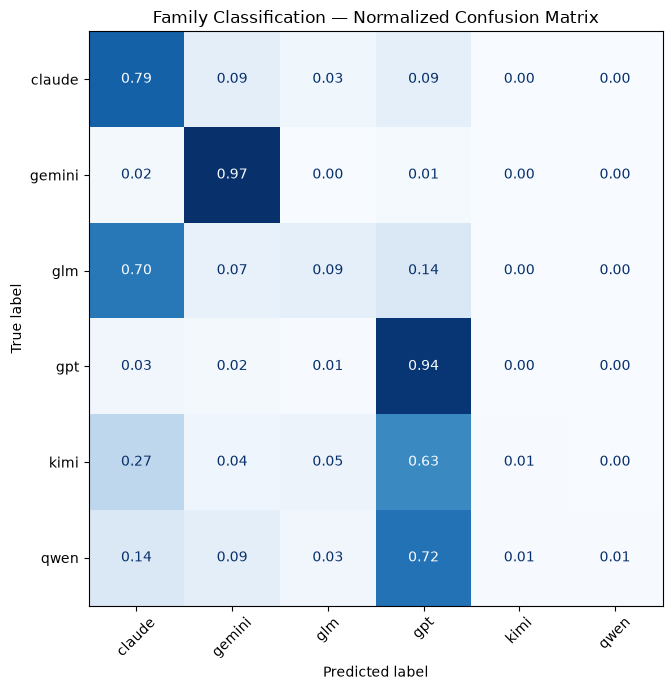

,count
Correct model,852
"Wrong model, correct family",914
Wrong family,933


Share of errors within the same family: 49.49 %


In [33]:
def get_family(model_name):
    if model_name.startswith("qwen"):
        return "qwen"
    return model_name.split("-")[0]


# Family labels: claude, gpt, gemini, glm, qwen, kimi
y_family = y.map(get_family)
family_names = sorted(y_family.unique())

display(y_family.value_counts())

# Out-of-fold predictions for both classifiers
flat_oof = np.empty(len(y), dtype=object)
family_oof = np.empty(len(y), dtype=object)

for fold_id, (train_idx, val_idx) in enumerate(folds):

    # Original 18-class classifier
    flat_model = build_char_model()
    flat_model.fit(
        X.iloc[train_idx],
        y.iloc[train_idx],
    )
    flat_oof[val_idx] = flat_model.predict(
        X.iloc[val_idx]
    )

    # Family-level classifier
    family_model = build_char_model()
    family_model.fit(
        X.iloc[train_idx],
        y_family.iloc[train_idx],
    )
    family_oof[val_idx] = family_model.predict(
        X.iloc[val_idx]
    )

# Derive family predictions from the flat classifier
flat_family_oof = pd.Series(flat_oof).map(get_family)

# Compare results
scores = pd.DataFrame({
    "experiment": [
        "Flat (18 models)",
        "Flat → family",
        "Direct family (6 families)",
    ],
    "balanced_accuracy": [
        balanced_accuracy_score(y, flat_oof),
        balanced_accuracy_score(y_family, flat_family_oof),
        balanced_accuracy_score(y_family, family_oof),
    ],
    "accuracy": [
        np.mean(y.to_numpy() == flat_oof),
        np.mean(y_family.to_numpy() == flat_family_oof),
        np.mean(y_family.to_numpy() == family_oof),
    ],
})

display(scores)

# Family confusion matrix
cm = confusion_matrix(
    y_family,
    family_oof,
    labels=family_names,
    normalize="true",
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=family_names,
)
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    colorbar=False,
)
ax.set_title("Family Classification — Normalized Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Analyze errors of the original 18-class classifier
true_models = y.to_numpy()
true_families = y_family.to_numpy()
pred_families = flat_family_oof.to_numpy()

correct_model = true_models == flat_oof
same_family = true_families == pred_families

error_summary = pd.Series({
    "Correct model": int(correct_model.sum()),
    "Wrong model, correct family": int(
        (~correct_model & same_family).sum()
    ),
    "Wrong family": int(
        (~same_family).sum()
    ),
})

display(error_summary.to_frame("count"))

total_errors = (~correct_model).sum()

print(
    "Share of errors within the same family:",
    round(
        100 * (~correct_model & same_family).sum()
        / total_errors, 2
    ) if total_errors else 0,
    "%"
)


### 5.1. Class Weight Balancing

Since model families have different numbers of training samples, we test whether class-weight balancing improves minority-family recognition.

We compare per-family recall and overall balanced accuracy using the same GroupKFold splits, with and without `class_weight="balanced"`.

,family,samples,recall_default,recall_balanced,delta
0,claude,749,0.7850,0.7236,-0.0614
1,gemini,600,0.9667,0.9733,0.0067
2,glm,300,0.0900,0.1933,0.1033
3,gpt,750,0.9413,0.9187,-0.0227
4,kimi,150,0.0067,0.0467,0.0400
5,qwen,150,0.0067,0.1067,0.1000


,variant,accuracy,balanced_accuracy
0,default,0.7051,0.4661
1,balanced,0.7025,0.4937


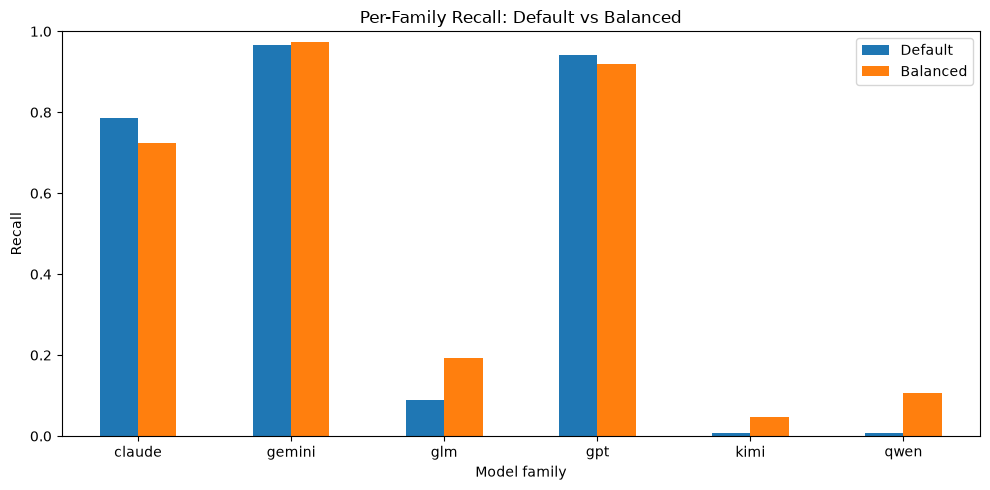

In [34]:
# Compare default and balanced family classifiers
def build_family_model(class_weight=None):
    return make_pipeline(
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=100_000,
        ),
        LinearSVC(
            C=1.0,
            max_iter=5000,
            class_weight=class_weight,
        ),
    )


predictions = {}

for name, weight in {
    "default": None,
    "balanced": "balanced",
}.items():

    oof_pred = np.empty(len(y_family), dtype=object)

    for train_idx, val_idx in folds:
        pipeline = build_family_model(
            class_weight=weight
        )

        pipeline.fit(
            X.iloc[train_idx],
            y_family.iloc[train_idx],
        )

        oof_pred[val_idx] = pipeline.predict(
            X.iloc[val_idx]
        )

    predictions[name] = oof_pred


# Per-family recall comparison
recall_rows = []

for family in family_names:
    mask = (y_family == family).to_numpy()

    recall_rows.append({
        "family": family,
        "samples": mask.sum(),
        "recall_default": np.mean(
            predictions["default"][mask] == family
        ),
        "recall_balanced": np.mean(
            predictions["balanced"][mask] == family
        ),
    })

recall_df = pd.DataFrame(recall_rows)

recall_df["delta"] = (
    recall_df["recall_balanced"]
    - recall_df["recall_default"]
)

display(recall_df.round(4))


# Overall metrics
metric_rows = []

for name, pred in predictions.items():
    metric_rows.append({
        "variant": name,
        "accuracy": np.mean(
            y_family.to_numpy() == pred
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_family, pred
        ),
    })

display(pd.DataFrame(metric_rows).round(4))


# Visualize per-family recall
plot_df = recall_df.set_index("family")[
    ["recall_default", "recall_balanced"]
]

ax = plot_df.plot.bar(
    figsize=(10, 5),
    rot=0,
)

ax.set_title("Per-Family Recall: Default vs Balanced")
ax.set_ylabel("Recall")
ax.set_xlabel("Model family")
ax.set_ylim(0, 1)
ax.legend(["Default", "Balanced"])

plt.tight_layout()
plt.show()


### 5.2. Results and Interpretation

Class-weight balancing improved family-level balanced accuracy from 46.61% to 49.37%, with only a minor reduction in overall accuracy.

Recall increased for underrepresented families (GLM, Kimi, and Qwen), while Claude and GPT showed moderate declines. However, minority-family recognition remained relatively poor.

These results suggest that class imbalance contributes to classification errors but does not fully explain them. Further analysis of cross-family confusion is needed.

,claude,gemini,glm,gpt,kimi,qwen
glm,0.593,0.063,0.193,0.12,0.020,0.010
kimi,0.207,0.033,0.100,0.60,0.047,0.013
qwen,0.113,0.093,0.027,0.64,0.020,0.107


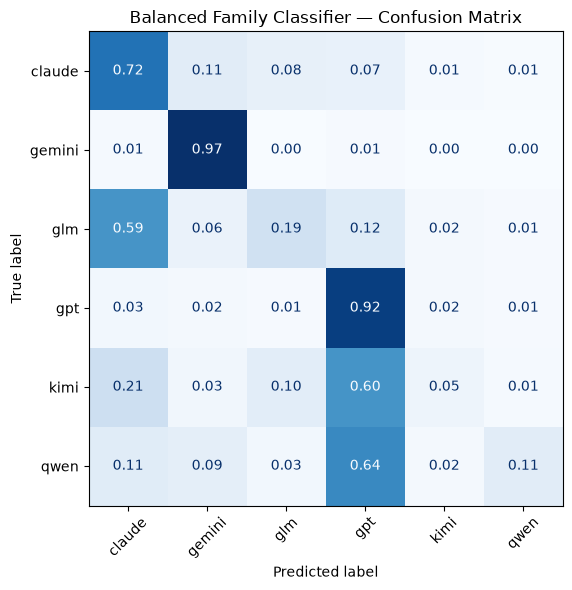

,true_family,predicted_family,error_share
0,glm,claude,0.593333
1,glm,gpt,0.120000
2,kimi,gpt,0.600000
3,kimi,claude,0.206667
4,qwen,gpt,0.640000
5,qwen,claude,0.113333


In [36]:
target_families = ["glm", "kimi", "qwen"]
balanced_pred = predictions["balanced"]

# Normalized confusion matrix
cm = confusion_matrix(
    y_family,
    balanced_pred,
    labels=family_names,
    normalize="true",
)

cm_df = pd.DataFrame(
    cm,
    index=family_names,
    columns=family_names,
)

# Show prediction distribution for minority families
display(
    cm_df.loc[target_families]
    .round(3)
)

# Visualize confusion patterns
fig, ax = plt.subplots(figsize=(9, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=family_names,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    colorbar=False,
)

ax.set_title("Balanced Family Classifier — Confusion Matrix")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Most frequent incorrect predictions
confusion_rows = []

for family in target_families:
    row = cm_df.loc[family].drop(family)

    for predicted_family, share in row.items():
        confusion_rows.append({
            "true_family": family,
            "predicted_family": predicted_family,
            "error_share": share,
        })

top_confusions = (
    pd.DataFrame(confusion_rows)
    .sort_values(
        ["true_family", "error_share"],
        ascending=[True, False],
    )
    .groupby("true_family")
    .head(2)
    .reset_index(drop=True)
)

display(top_confusions)

## 5.3. Results and Interpretation

The balanced classifier identifies Gemini (97%) and GPT (92%) reliably, while GLM (19%), Qwen (11%), and Kimi (5%) remain difficult to distinguish.

Misclassifications are highly asymmetric: GLM is frequently predicted as Claude (59%), whereas Kimi and Qwen are predominantly predicted as GPT (60% and 64%).

These results suggest that class imbalance alone does not explain the errors. Further analysis of pairwise discriminative features is needed to identify which textual patterns contribute to these systematic confusions.

## Next Steps — Notebook 03: Pairwise Classification

In `03_pairwise_classification.ipynb`, we will evaluate targeted binary classifiers for GLM vs Claude, Kimi vs GPT, and Qwen vs GPT. We will compare their balanced accuracy and pairwise feature contributions using prompt-grouped cross-validation, then test whether they improve the final 18-model classification when integrated into a refinement pipeline. All model selection and routing decisions must be evaluated without using held-out prompts to tune them.